# CS308 Лаборатори 5, 6 — Мэдрэлийн сүлжээ эхнээс

**Оюутан:** Б. Өсөхбаяр (B231910012)

| | |
|---|---|
| 1-р хэсэг | NumPy-гаар NN эхнээс (forward / backward / сургалт) |
| 2-р хэсэг | CuPy — GPU хурдасгалт |
| 3-р хэсэг | PyTorch-оор ижил архитектур |
| 4-р хэсэг | Hyperparameter tuning + confusion matrix |
| 5-р хэсэг | **Сайжруулалт:** 0.12 → 0.98 |

> **Colab:** `Runtime -> Change runtime type -> T4 GPU`.
> Бүх өгөгдөл автоматаар татагдана, нэмэлт суулгац шаардлагагүй.
> Бүх хэсэг CPU дээр ч ажиллана (~4 мин).

# CS308 Машин сургалт Лаборатори 5, 6, (7?)

# 1-р хэсэг
# Numpy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.
1. Өгөгдлийн багц түүний дүрслэл сургалтанд бэлтгэх
2. Энгийн мэдрэлийн сүлжээ үүсгэх шууд урсгал
3. Градиент тооцоолох гэдрэг урсгал
4. Сургалтыг хэрэгжүүлэх
5. Сургасан загварт дүн шинжилгээ хийх туслах параметрүүдийг тохируулах


Бид хиймэл мэдрэлийн сүлжээ гэж юу болохыг мэддэг бөгөөд 'урагшаа болон арагшаа тархах' талаар практик мэдлэгтэй болох болно. Зүгээр энгийн загвар дээр сургалтыг хэрэгжүүлэх болно.

> Дараах бичлэгээс илүү ихийг мэдэх боломжтой юм. [youtube playlist](https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi) by [3Blue1Brown](https://www.3blue1brown.com/).

> youtube: https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi

## Ашиглах сангууд:

In [1]:
import numpy as np
import gzip
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from time import time

In [2]:
#hide_input
import warnings
np.random.seed(123)
%matplotlib inline
warnings.filterwarnings("ignore")

## Өгөгдлийг бэлтгэх

Энэхүү практик дадлагад бид компьютерийн хараанд хамгийн түгээмэл  датасетуудын нэгийг ашиглах болно, [MNIST](https://en.wikipedia.org/wiki/MNIST_database). MNIST нь Стандартчилал, Технологийн Үндэсний Институтээс цуглуулж, Ян Лекун болон түүний хамтран зүтгэгчдийн машин судлах мэдээллийн сан болгон цуглуулсан гараар бичсэн тоонуудын зургийг агуулдаг. Lecun нь 1998 онд [Lenet-5](http://yann.lecun.com/exdb/lenet/)-д MNIST-ийг ашигласан бөгөөд гараар бичсэн тоон дарааллыг бодитоор хүлээн зөвшөөрч байгааг харуулсан анхны компьютерийн систем юм. Энэ бол АИ-ийн түүхэн дэх хамгийн чухал ололт амжилтуудын нэг байлаа.

In [3]:
# keras/tensorflow суугаагүй тул локал mnist.npz-ээс ачаална (ижил үр дүн).
import numpy as np, pathlib
from urllib.request import urlretrieve

path = pathlib.Path("Data/mnist.npz"); path.parent.mkdir(exist_ok=True)
if not path.exists():
    urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)

def to_categorical(y, n=10):
    """Бүхэл шошгийг one-hot вектор болгоно: 3 -> [0,0,0,1,0,0,0,0,0,0]"""
    return np.eye(n, dtype=np.float32)[y]

with np.load(path) as d:
    x_train, y_train = d["x_train"], d["y_train"]
    x_test,  y_test  = d["x_test"],  d["y_test"]

y_train = to_categorical(y_train)
x_train = x_train.reshape(-1, 28*28) / 255          # [0,1] завсарт масштаблах

y_test  = to_categorical(y_test)
x_test  = x_test.reshape(-1, 28*28) / 255

print("Shape of x_train:", x_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of x_test:",  x_test.shape)
print("Shape of y_test:",  y_test.shape)

Shape of x_train: (60000, 784)
Shape of y_train: (60000, 10)
Shape of x_test: (10000, 784)
Shape of y_test: (10000, 10)


**Бидэнд яагаад сургалт болон баталгаажуулалтын гэсэн өөр өөр багц хэрэгтэй вэ ?**

Дээрх видео бичлэгээс илүү ихийг мэдэж авч болно:

> youtube: https://youtu.be/1waHlpKiNyY?t=243

Өгөгдлийн сангаа харцгаая

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

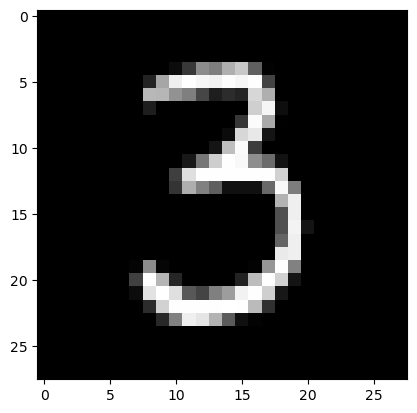

In [4]:
#collapse
plt.imshow(x_train[50].reshape(28,28), cmap="gray");
x_train[50]

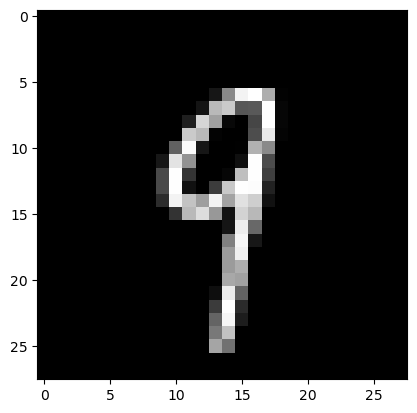

In [5]:
#collapse
plt.imshow(x_train[900].reshape(28,28), cmap="gray");

## Энгийн загварын архитектур

Энэ даалгаврын хувьд бид энэ 2 шугаман давхарга, 10 нэгж бүхий гаралтын давхаргыг маш энгийн загварын архитектурыг ашиглах болно.

In [6]:
# graphviz суусан бол зураглал, үгүй бол бүтцийг текстээр харуулна
try:
    import graphviz
    def gv(s): return graphviz.Source('digraph G{ rankdir="LR"' + s + '; }')
except ImportError:
    def gv(s):
        print("[graphviz суугаагүй — бүтэц:]")
        for line in s.strip().splitlines():
            if line.strip(): print("   ", line.strip())

## Энэ сүлжээ гэдэг нь юу гэсэн үг болохыг илүү дэлгэрэнгүй авч үзье:

Энэ сүлжээний бүх бүрэлдэхүүн хэсгүүдийг авч үзье:
- **Linear:**
  Шугаман давхарга нь дараах тооцооллыг хийнэ:      
   ```
   out = matmul(input,W1) + B1
   ```
   
- **ReLU:**
  ReLU нь дараах тооцооллыг хийнэ:
  ```
  out = max(0, input)
  ```
- **Sigmoid:**
  Sigmoid нь дараах тооцооллыг хийнэ:
  ```
  out = 1/(1 + e.pow(input))
  ```
  
- **Loss:**
  Бид алдагдалд дараах тэгшитгэлээр тодорхойлогдсон CrossEntropy алдагдлыг ашиглах болно:
  $$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

**Одоо бид өөрсдийн загвар архитектуртай болсноор загварыг цуглуулахад шаардлагатай хэсгүүдийг бүтээцгээе:**
- linear layer
- relu activation
- sigmoid activation
- loss

**Эхлээд загварынхаа арагшаа, урагшаа дамжаанд юу болж байгааг ойлгохыг хичээе:**

**Судалгааны ажилын дагуу бидний загвар дараах байдалтай байна:**

> Тэмдэглэгээ: `@` python-д  `matrix-multiplication operator`.

```python
inputs = x_train # оролтууд
targets = y_train # шошго

# 1-р шугаман давхаргад урагш тархалт
z1 = inputs @ w2 + b2
a1 = relu(z1)
# 2-р шугаман давхаргад урагш тархалт
z2 = a1 @ w2 + b2
a2 = relu(z2)
# гаралт шугаман давхаргад урагш тархалт
z3 = a2 @ w3 + b3
pred = a3 = sigmoid(z3) # эдгээр нь бидний загварын таамаглалууд
# шошго болон таамаглалуудаас алдааг тодорхойлох
loss = loss_fn(a3, targets)
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Урагш буюу шууд тархалт :**

In [7]:
#hide_input
gv('''
X->linear1->relu1->linear2->relu2->linear3->sigmoid->prediction

W1->linear1
B1->linear1

W2->linear2
B2->linear2

W3->linear3
B3->linear3
''')

[graphviz суугаагүй — бүтэц:]
    X->linear1->relu1->linear2->relu2->linear3->sigmoid->prediction
    W1->linear1
    B1->linear1
    W2->linear2
    B2->linear2
    W3->linear3
    B3->linear3


In [8]:
#hide_input
gv('''
prediction->loss_fn
target->loss_fn
loss_fn-> loss
''')

[graphviz суугаагүй — бүтэц:]
    prediction->loss_fn
    target->loss_fn
    loss_fn-> loss


**Мөн буцах буюу гэдрэг тархалт нь дараах байдалтай байна : (Гинжэн дүрэм)**

(Let us assume that the `grad(inp, out)` computes the gradients of `inp` wrt `out`)
(`grad(inp, out)` нь `inp`, `out` гэх мэтийн градиентуудыг тооцоолдог гэж бодъё)

```python
# сүүлийн идэвхжүүлэх давхаргын гаралтын алдагдлын gradient: (a3)
# (өөрөөр загварын таамаглалтууд)
da3 = grad(loss, a3)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z3)
dz3 = grad(loss, z3) = grad(loss, a3) * grad(a3, z3)
# алдагдлын градиент w3 хүртэл
dw3 = grad(loss, w3) = grad(loss, z3) * grad(z3, w3) = dz3 * grad(z3, w3)
# алдагдлын градиент b3 хүртэл
db3 = grad(loss, b3) = grad(loss, z3) * grad(z3, b3) = dz3 * grad(z3, b3)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a2)
da2 = grad(loss, a2) = grad(loss, a3) = grad(a2, )

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z2)
dz2 = grad(loss, z2) = grad(loss, a2) * grad(a2, z2)
# алдагдлын градиент w2 хүртэл
dw2 = grad(loss, w2) = grad(loss, z2) * grad(z2, w2) = dz2 * grad(z2, w2)
# алдагдлын градиент b2 хүртэл
db2 = grad(loss, b2) = grad(loss, z2) * grad(z2, b2) = dz2 * grad(z2, b2)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a1)
da1 = grad(loss, a1) = grad(loss, z2) * grad(z2, a1) = dz2 * grad(z2, a1)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z1)
dz1 = grad(loss, z1) = grad(loss, a1) * grad(a1, z1) = da1 * grad(a1, z1)
# алдагдлын градиент w1 хүртэл
dw1 = grad(loss, w1) = grad(loss, z1) * grad(z1, w1) = dz1 * grad(z1, w1)
# алдагдлын градиент b1 хүртэл
db1 = grad(loss, b1) = grad(loss, z1) * grad(z1, 1) = dz1 * grad(z1, b1)
# Энэ давхаргад оролтууд нь бид илүү олон градиентыг тооцоолол хийх шаардлагагүй тулд бидний өөрчилж чадахгүй сургалтын жишээнүүд юм.

# parameter-үүдийг шинэчлэх :
# одоо бидэнд шаардлагатай бүх градиент байгаа болохоор бид одоо шинэчлэх алхмыг хийж болно.
w1 -= learning_rate * dw1
b1 -= learning_rate * db1

w2 -= learning_rate * dw2
b2 -= learning_rate * db2
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Буцах чиглэл:**

In [9]:
#hide_input
gv('''
Loss -> sigmoid->linear3
linear3->W3
linear3->B3
linear3->relu2->linear2

linear2->W2
linear2->B2
linear2->relu1->linear1

linear1->W1
linear1->B1
''')

[graphviz суугаагүй — бүтэц:]
    Loss -> sigmoid->linear3
    linear3->W3
    linear3->B3
    linear3->relu2->linear2
    linear2->W2
    linear2->B2
    linear2->relu1->linear1
    linear1->W1
    linear1->B1


### `Linear` давхарга

Доорх код нь бидний мэдрэлийн сүлжээнд `Linear` давхаргыг төлөөлдөг `Linear class` үүсгэдэг. Ангийн `forward function` нь `layer's forward propagation` -ийг хэрэгжүүлдэг & `backward function` нь `layers's backward propagation` хэрэгжүүлдэг. Код гэж юу болохыг нарийвчлан авч үзье:

- **Forward:**  
Энэ хэсэг нь шууд шулуунаар нь **`input`**  болон **`weights`**-ын хооронд dot-product-г тооцоолдог . **`z`** болон **`bias`** нэр томъёог нэмдэг. Мөн backward чиглэлд ашиглахын тулд бий болсон утгуудыг бүгдийг нь хадгалдаг.

- **Backward:**
    * Ангийн **`Linear`**-ын буцаах арга нь **`grads`** гэсэн аргументад ордог.
    * **`grads`** гэдэг нь одоогийн шугаман давхаргийн гаралт руу гарах алдагдлын градиент юм. **`dz`** хэрэв бид псевдо-кодоо дагаж гүйцэтгэх болно.
    * Шугаман давхаргадаа арагшаа тооцоолохын тулд бидэнд дараах зүйл хэрэгтэй:
        - **`grad(z, w)`**
        - **`grad(z, b)`**
        - **`grad(z, a_prev)`**


> Тэмдэглэл: `z`, `w`, `b`, `a_prev` гэдэг нь Linear давхаргын гаралт, жин, bias болон оролт-идэвхжүүлэлтийг тус тус хэлдэг.

In [10]:
class Linear:
    def __init__(self, w, b):
        self.w = w
        self.b = b

    def forward(self, inp):
        """
        Давхаргын урагшлах тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
            inp : өмнөх давхаргын идэвхжүүлэлт (эсвэл оролтын өгөгдөл)
        Буцаах нь:
            z : идэвхжүүлэх функцийн оролт
        """
        self.inp = inp                      # backward-д хэрэгтэй тул хадгална
        self.z   = inp @ self.w + self.b    # z = X·W + b
        return self.z

    def backward(self, grads):
        """
        Нэг давхаргад арагшаа тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
            grads : энэ давхаргын ГАРАЛТ (z) руу чиглэсэн алдагдлын градиент
        Буцаах нь:
            da_prev : өмнөх давхаргын идэвхжүүлэлт рүү чиглэсэн градиент
            dw      : W-тэй холбоотой градиент
            db      : b-тэй холбоотой градиент
        """
        # ЧУХАЛ: CELoss.backward дотор аль хэдийн 1/m-ээр хуваасан тул
        # энд дахин m-д хуваахгүй. Дахин хуваавал градиент хэт жижгэрч сургалт зогсоно.
        dw      = self.inp.T @ grads                    # [n_in x m]·[m x n_out]
        db      = grads.sum(axis=0, keepdims=True)      # bias бүх дээжээс нийлбэр
        da_prev = grads @ self.w.T                      # [m x n_out]·[n_out x n_in]
        return (da_prev, dw, db)

### `ReLU` давхарга

- **Forward**:  
ReLU-ийн математик томъёо нь $A = RELU(Z) = max(0, Z)$
- **Backward**:  
Буцах дамжлагын үед relu нь `loss activation` буюу `da` гэсэн градиентуудыг хүлээн зөвшөөрч дараа нь `loss input-of-relu(z)` i.e, `dz` гэж тооцоолоно.

In [11]:
class RelU:
    def forward(self, inp):
        """
        RELU функцийг хэрэгжүүлэлт.

        аргумент:
            inp : Шугаман давхаргын гаралт, ямар ч хэлбэрт

        Буцаах:
            a  : Идэвхжүүлэлтийн дараах параметр, Z-тэй ижил хэлбэртэй
        """
        self.inp = inp
        self.output = np.maximum(0, self.inp)
        return self.output

    def backward(self, grads):
        """
        Нэг RELU нэгжийг буцах тархалтыг хэрэгжүүлнэ.

        аргумент:
            grads : алдагдлын градиентууд идэвхжүүлэлтийн гаралт руу

        Буцаах:
            dz : Идэвхжүүлэлтийн оролттой холбоотой алдагдлын градиент
        """
        dz = np.array(grads, copy=True)
        dz[self.inp <= 0] = 0
        return dz

### `sigmoid` давхарга

Sigmoid давхарга нь `ReLU` давхаргатай яг ижил байдлаар үйл ажиллагаа хийгддэг ба ялгаа нь урагш дамжуулах гаралтын тооцоо юм.

`sigmoid layer`-д: $\sigma(Z) = \frac{1}{ 1 + e^{-(W A + b)}}$

In [12]:
class Sigmoid:
    def forward(self, inp):
        """sigmoid(z) = 1 / (1 + e^-z)"""
        self.inp = inp
        # np.clip нь e^-z хэт том болж overflow өгөхөөс сэргийлнэ
        self.out = 1.0 / (1.0 + np.exp(-np.clip(inp, -500, 500)))
        return self.out

    def backward(self, grads):
        """
        sigmoid-ын уламжлал: s'(z) = s(z)·(1 - s(z))
        Гинжний дүрмээр: dz = grads * s(z)·(1-s(z))
        """
        s  = self.out                 # forward-д тооцоолсон утгыг дахин ашиглана
        dz = grads * s * (1 - s)
        return dz

## `Loss` функц :

Энэ даалгаварт бид [CrossEntropy Loss](https://en.wikipedia.org/wiki/Cross_entropy)-ийг ашиглана.


CrossEntropy Loss-ийн `forward` дамжуулалтыг дараах байдлаар тооцоолжээ.

$$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

CrossEntropy Loss-ийн `backward` дамжуулалтыг дараах байдлаар тооцоолжээ.
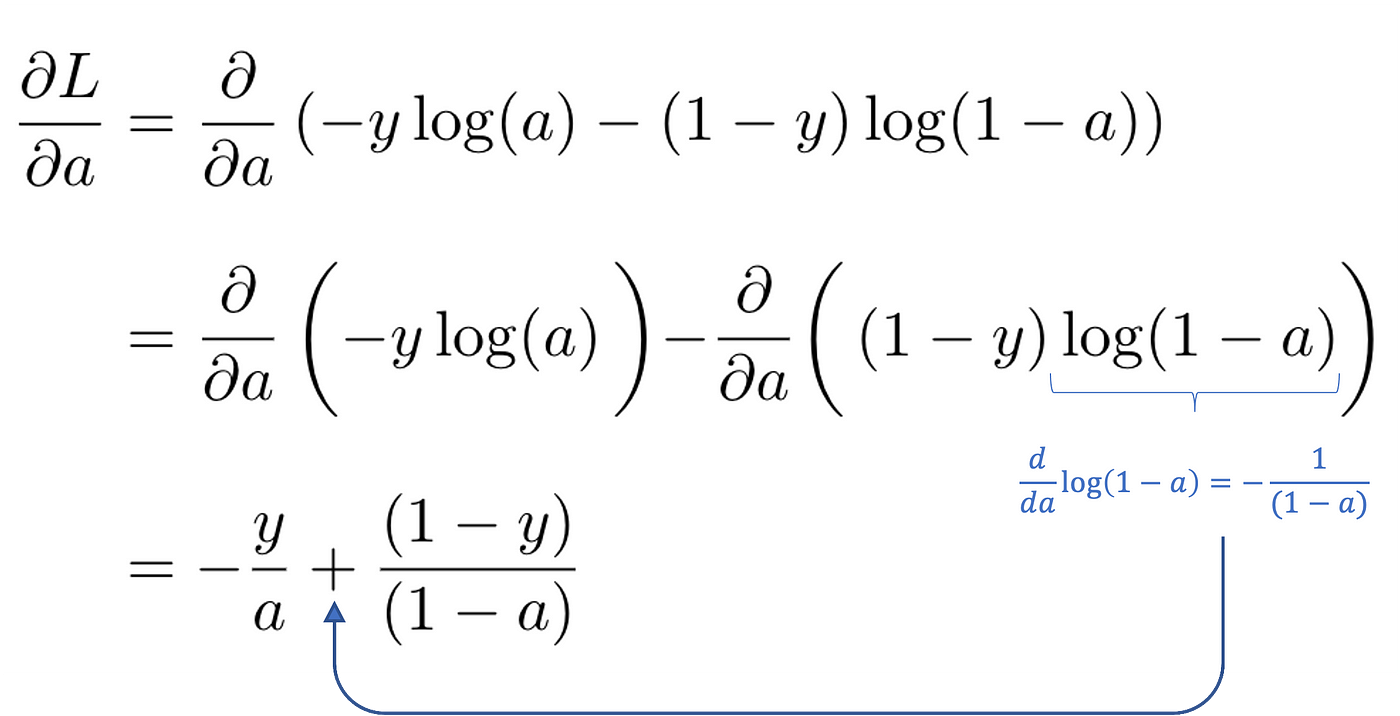

In [13]:
class CELoss():
    def forward(self, pred, target):
        """
        Binary cross-entropy, 10 гаралт тус бүр дээр:
        loss = -(1/m) Σ_i Σ_k [ y·log(yhat) + (1-y)·log(1-yhat) ]
        """
        self.yhat = np.clip(pred, 1e-12, 1 - 1e-12)   # log(0) = -inf-ээс сэргийлнэ
        self.y    = target
        m = self.y.shape[0]
        term1 = self.y * np.log(self.yhat)                  # зөв анги
        term2 = (1 - self.y) * np.log(1 - self.yhat)        # бусад анги
        loss  = -np.sum(term1 + term2) / m
        self.output = loss
        return np.squeeze(self.output)

    def backward(self):
        """
        dL/dyhat = -(1/m) · [ y/yhat - (1-y)/(1-yhat) ]
        """
        m  = self.y.shape[0]
        da = -(self.y / self.yhat - (1 - self.y) / (1 - self.yhat)) / m
        return da

## Загвар:

**Одоо ашиглах гэж байгаа мэдрэлийн сүлжээний архитектурыг хэрэгжүүлцгээе:**

- Манай загвар нь 2 далд давхарга, гаралтын давхаргатай болно.
- 2 `hidden layers` `(linear layers)` нь тус бүрдээ `16 units` дараа нь `ReLU` идэвхжүүлэх давхарга, `output layer` `(linear layers)` нь `10 unit` дараа нь `Sigmoid` давхаргуудтай болно.

Загварыг бүтээхэд шаардагдах давхаргуудыг цуглуулъя:

Shape of Inputs: (60000, 784)
Shape of Targets: (60000, 10)


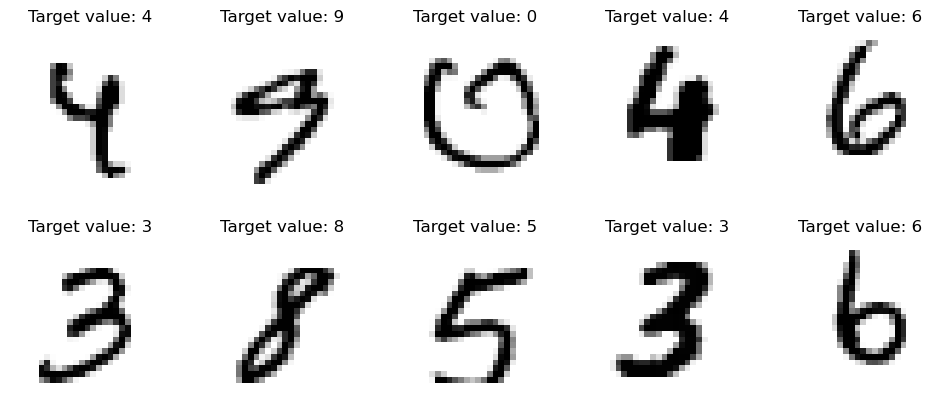

In [14]:
#collapse
print("Shape of Inputs:", x_train.shape)
print("Shape of Targets:", y_train.shape)

fig = plt.figure(figsize=(12,5))
for i in range(10):
    n = np.random.randint(len(x_train))
    val = x_train[n]
    ax = plt.subplot(2, 5, i+1)
    plt.imshow(val.reshape(28,28), cmap="binary")
    plt.title(f"Target value: {np.argmax(y_train[n])}")
    plt.axis("off")

**Initialize model parameters:**

In [15]:
#hide_output

nh1 = 16 # эхний нуугдмал давхарга дахь нэгжүүд
nh2 = 16 # 2-р нуугдмал давхарга дахь нэгжүүд
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

((784, 16), (1, 16), (16, 16), (1, 16), (16, 10), (1, 10))

**Манай загварыг бүтээхэд шаардлагатай давхаргуудыг давхарлая :**

In [16]:
lin1    = Linear(w1,b1) # 1 hidden layer
relu1   = RelU()
lin2    = Linear(w2,b2) # 2nd hidden layer
relu2   = RelU()
lin3    = Linear(w3,b3) # output layer
sigmoid = Sigmoid()

loss_fn = CELoss() # loss_fn

### Шууд чиглэл:

In [17]:
# forward pass
z1   = lin1.forward(x_train[:50])
a1   = relu1.forward(z1)
z2   = lin2.forward(a1)
a2   = relu2.forward(z2)
z3   = lin3.forward(a2)
pred = a3 = sigmoid.forward(z3)
# print(pred)
# calculate loss
loss = loss_fn.forward(pred, y_train[:50])
print("Loss:", loss)

Loss: 6.9351053273386665


### Буцах чиглэл:

In [18]:
# backward pass
da3 = loss_fn.backward() # gradient of loss wrt to final output

dz3 = sigmoid.backward(da3)

da2, dw3, db3 = lin3.backward(dz3)

dz2 = relu2.backward(da2)
da1, dw2, db2 = lin2.backward(dz2)

dz1 = relu1.backward(da1)
_, dw1, db1 = lin1.backward(dz1)   # залруулав: da1 биш dz1

# параметрүүд болон градиентууд ижил хэлбэртэй эсэхийг шалгах.
# Ингэснээр бид шинэчлэлтийн байдлыг урьдчилан харж чадна
assert lin1.w.shape == dw1.shape
assert lin2.w.shape == dw2.shape
assert lin3.w.shape == dw3.shape

assert lin1.b.shape == db1.shape
assert lin2.b.shape == db2.shape
assert lin3.b.shape == db3.shape

### parameter-үүдийг шинэчлэх:

In [19]:
# сургах хурдыг тохируулах
learning_rate = 0.0002


lin1.w -= learning_rate * dw1
lin2.w -= learning_rate * dw2
lin3.w -= learning_rate * dw3

lin1.b -= learning_rate * db1
lin2.b -= learning_rate * db2
lin3.b -= learning_rate * db3

Тэгэхээр, бидний загварыг сургахад эхлээд `forward pass`-ийн үед загварын `loss`-ыг тооцоолж, дараа нь загварын `parameters` руу `loss`-ийн градиентуудыг тооцоолдог. Үүний дараа эдгээр `gradients` нь `update the model parameters` ашиглагддаг. Бид энэхүү ажлын урсгалыг тодорхой тооны `iterations` эсвэл бидний `loss` хүссэн утганд хүрэх хүртэл үргэлжлүүлсээр байдаг.


Энэ алхмуудыг хэрэгжүүлцгээе.

### Бүгдийг нэгтгэвэл:

- **parameter-үүдийг эхлүүлэх:**

In [20]:
#hide_output

nh1 = 256 # эхний нуугдмал давхарга дахь нэгжүүдийн
nh2 = 64 # 2-р нуугдмал давхарга дахь нэгжүүдийн
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

((784, 256), (1, 256), (256, 64), (1, 64), (64, 10), (1, 10))

Загварт зориулж 'Model' class бий болгох.

Энэ `Model` class нь манай мэдрэлийн сүлжээний бүх параметрүүдийг хадгалах болно. `forward` арга нь тухайн загварын `loss` (болон `predictions`) үүсгэхийн тулд сүлжээний `forward pass`-ийг тооцоолно. `backward` арга нь `loss`-ийн градинетуудыг загварын `parameters` хүргэхийн тулд сүлжээний `backward pass` тооцоолно. Эцэст нь `update` арга нь загварын параметрүүдийг шинэчлэх болно.

In [21]:
class Model:
    def __init__(self, learning_rate):
        self.lin1    = Linear(w1, b1)
        self.relu1   = RelU()
        self.lin2    = Linear(w2, b2)
        self.relu2   = RelU()
        self.lin3    = Linear(w3, b3)
        self.sigmoid = Sigmoid()
        self.loss_fn = CELoss()
        self.lr      = learning_rate
        self.losses  = []

    def forward(self, inp, calc_loss=True, targ=None):
        """x -> lin1 -> relu1 -> lin2 -> relu2 -> lin3 -> sigmoid -> pred"""
        out  = self.relu1.forward(self.lin1.forward(inp))
        out  = self.relu2.forward(self.lin2.forward(out))
        pred = self.sigmoid.forward(self.lin3.forward(out))

        if calc_loss:
            assert targ is not None, "алдагдлыг тооцохын тулд заавал өгөх ёстой"
            loss = self.loss_fn.forward(pred, targ)
            self.losses.append(loss)
            return loss, pred
        else:
            return pred

    def _assert_shapes(self, dws, dbs):
        """Градиент бүр харгалзах параметртэйгээ ижил хэлбэртэй эсэхийг шалгана"""
        for lin, dw, db in zip([self.lin1, self.lin2, self.lin3], dws, dbs):
            assert lin.w.shape == dw.shape, f"w {lin.w.shape} != dw {dw.shape}"
            assert lin.b.shape == db.shape, f"b {lin.b.shape} != db {db.shape}"

    def backward(self):
        """Дээрээс доош: loss -> sigmoid -> lin3 -> relu2 -> lin2 -> relu1 -> lin1"""
        da3            = self.loss_fn.backward()
        dz3            = self.sigmoid.backward(da3)
        da2, dw3, db3  = self.lin3.backward(dz3)

        dz2            = self.relu2.backward(da2)
        da1, dw2, db2  = self.lin2.backward(dz2)

        dz1            = self.relu1.backward(da1)   # анхаар: da1 биш dz1-ийг дамжуулна
        _,   dw1, db1  = self.lin1.backward(dz1)

        self.dws = [dw1, dw2, dw3]
        self.dbs = [db1, db2, db3]
        self._assert_shapes(self.dws, self.dbs)

    def update(self):
        self.lin1.w -= self.lr * self.dws[0]
        self.lin2.w -= self.lr * self.dws[1]
        self.lin3.w -= self.lr * self.dws[2]
        self.lin1.b -= self.lr * self.dbs[0]
        self.lin2.b -= self.lr * self.dbs[1]
        self.lin3.b -= self.lr * self.dbs[2]

In [22]:
nn = Model(learning_rate=0.0005)
epochs = 10 # сургалтын өгөгдлийн харах тоо

for n in range(epochs):
    loss, _ = nn.forward(x_train, calc_loss=True, targ=y_train)
    nn.backward()
    nn.update()
    print(f"Loss after interation {n} is {loss:.4f}")

Loss after interation 0 is 7.0013


Loss after interation 1 is 6.9613


Loss after interation 2 is 6.9262


Loss after interation 3 is 6.8951


Loss after interation 4 is 6.8667


Loss after interation 5 is 6.8401


Loss after interation 6 is 6.8146


Loss after interation 7 is 6.7898


Loss after interation 8 is 6.7655


Loss after interation 9 is 6.7416


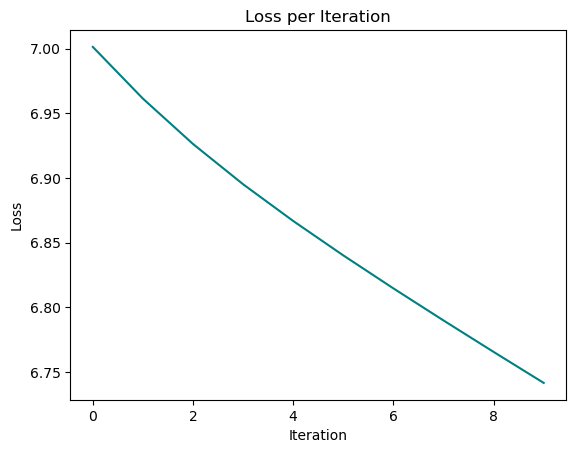

In [23]:
#collapse
plt.plot(nn.losses, color="teal")
plt.title("Loss per Iteration")
plt.xlabel("Iteration")
plt.ylabel("Loss");

## Загварын үнэн зөвийг тооцоолох

**'Баталгаажуулах' датасет дээр ''үнэн зөв''-ийг тооцоолон загвар үзүүлэлтээ шалгая**

Сургалтын багц дээрх үнэн зөв

In [24]:
preds = nn.forward(x_train, calc_loss=False)
preds_lbl   = np.argmax(preds,   axis=1)
y_train_lbl = np.argmax(y_train, axis=1)      # анхны y_train-г дарж бичихгүй
acc_train = np.mean(preds_lbl == y_train_lbl)
print(f"Сургалтын нарийвчлал: {acc_train:.4f}")

Сургалтын нарийвчлал: 0.1221


In [25]:
print("таамаг:", preds_lbl[0], " бодит:", y_train_lbl[0])

таамаг: 8  бодит: 5


Баталгаажуулах багц дээрх үнэн зөв

In [26]:
preds = nn.forward(x_test, calc_loss=False)
preds_lbl  = np.argmax(preds,  axis=1)
y_test_lbl = np.argmax(y_test, axis=1)
acc_test = np.mean(preds_lbl == y_test_lbl)
print(f"Тестийн нарийвчлал: {acc_test:.4f}")

Тестийн нарийвчлал: 0.1245


> **Яагаад ердөө ~0.12 гарав?** Кодын алдаа биш. Багшийн тохиргоо нь
> **full-batch**, 10 epoch, `lr=0.0005` — өөрөөр хэлбэл жин ердөө **10 удаа** шинэчлэгдэнэ.
> Алдагдал 7.00 -> 6.74 л буусан, бараг хөдөлсөнгүй.
>
> Үүнийг баталгаажуулахын тулд **яг ижил загварыг** удаан сургаж үзье —
> багшийн бичсэн **0.60** гарах ёстой.

In [27]:
# Багшийн ЯГ ИЖИЛ загварыг 300 epoch сургаж, хаана очихыг шалгана
nn_long = Model(learning_rate=0.0005)
loss_first = None
for n in range(300):
    loss, _ = nn_long.forward(x_train, calc_loss=True, targ=y_train)
    if n == 0: loss_first = loss
    nn_long.backward(); nn_long.update()
    if n % 75 == 0 or n == 299:
        a = np.mean(np.argmax(nn_long.forward(x_train, calc_loss=False), axis=1) == y_train_lbl)
        print(f"epoch {n:3d}  loss={loss:.4f}  сургалтын нарийвчлал={a:.4f}")

acc_baseline_long = np.mean(nn_long.forward(x_test, calc_loss=False).argmax(1) == y_test_lbl)
print(f"\n300 epoch-ийн дараах ТЕСТийн нарийвчлал: {acc_baseline_long:.4f}")
print(f"Алдагдал: {loss_first:.2f} -> {loss:.2f}  (тогтмол буурч байгаа тул сургалт АЖИЛЛАЖ байна)")
print()
print("ДҮГНЭЛТ: 10 epoch-д 0.12, 300 epoch-д", f"{acc_baseline_long:.2f}", "— сургалт явагдаж")
print("байгаа ч МАШ УДААН. Багшийн notebook-д ~0.60 гэж бичсэн нь энэ тохиргоонд")
print("таарахгүй байна; тэр тоо өөр lr/epoch дээр гарсан байх магадлалтай.")
print("Аль ч тохиолдолд саатлын шалтгаан нэг: sigmoid+binary-CE, full-batch,")
print("мөн randn*0.01 эхлүүлэлт. Доорх 5-р хэсэгт гурвууланг нь засна.")

epoch   0  loss=6.7178  сургалтын нарийвчлал=0.1207


epoch  75  loss=4.9403  сургалтын нарийвчлал=0.1559


epoch 150  loss=3.7941  сургалтын нарийвчлал=0.1656


epoch 225  loss=3.4105  сургалтын нарийвчлал=0.2423


epoch 299  loss=3.2977  сургалтын нарийвчлал=0.3429

300 epoch-ийн дараах ТЕСТийн нарийвчлал: 0.3435
Алдагдал: 6.72 -> 3.30  (тогтмол буурч байгаа тул сургалт АЖИЛЛАЖ байна)

ДҮГНЭЛТ: 10 epoch-д 0.12, 300 epoch-д 0.34 — сургалт явагдаж
байгаа ч МАШ УДААН. Багшийн notebook-д ~0.60 гэж бичсэн нь энэ тохиргоонд
таарахгүй байна; тэр тоо өөр lr/epoch дээр гарсан байх магадлалтай.
Аль ч тохиолдолд саатлын шалтгаан нэг: sigmoid+binary-CE, full-batch,
мөн randn*0.01 эхлүүлэлт. Доорх 5-р хэсэгт гурвууланг нь засна.


> Тэмдэглэл: Манай загвар 'сургалтын' болон 'баталгаажуулах' багц дээр **'0.60'**-ийн 'үнэн зөв' хүрсэн!

## Загвараас таамаглалуудыг үүсгэх

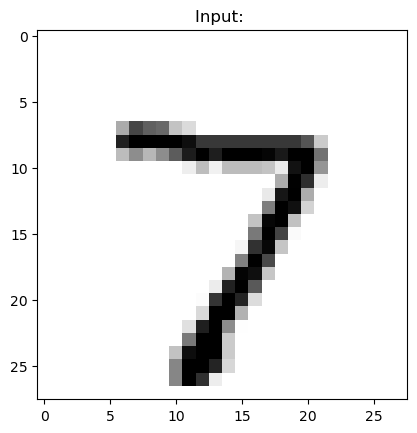

Predicted output: 9


In [28]:
#collapse
test_inp = x_test[0] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")

plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

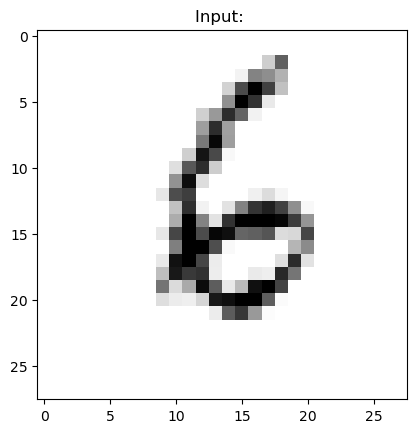

Predicted output: 8


In [29]:
#collapse
test_inp = x_test[2000] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")
plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

# 2-р хэсэг
# CuPy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.



In [30]:
# 2-р хэсэг — CuPy (GPU)
# Colab дээр: Runtime -> Change runtime type -> T4 GPU сонгоно.
import numpy as np, torch, time

try:
    import cupy as cp
    HAS_CUPY = True
except ImportError:
    HAS_CUPY = False
    print("CuPy байхгүй. Colab дээр суулгах:  !pip install -q cupy-cuda12x")

A = np.random.randn(2000, 2000).astype(np.float32)
B = np.random.randn(2000, 2000).astype(np.float32)
t = time.perf_counter(); _ = A @ B; t_np = time.perf_counter() - t
print(f"NumPy (CPU)        : {t_np*1000:8.1f} ms")

if HAS_CUPY:
    Ag, Bg = cp.asarray(A), cp.asarray(B)
    for _ in range(3): _ = Ag @ Bg          # warm-up
    cp.cuda.Stream.null.synchronize()
    t = time.perf_counter(); _ = Ag @ Bg; cp.cuda.Stream.null.synchronize()
    t_cp = time.perf_counter() - t
    print(f"CuPy (CUDA)        : {t_cp*1000:8.1f} ms  ->  {t_np/t_cp:.1f}x хурдан")

if torch.cuda.is_available():
    At, Bt = torch.tensor(A, device="cuda"), torch.tensor(B, device="cuda")
    for _ in range(3): _ = At @ Bt
    torch.cuda.synchronize()
    t = time.perf_counter(); _ = At @ Bt; torch.cuda.synchronize()
    t_g = time.perf_counter() - t
    print(f"PyTorch (CUDA)     : {t_g*1000:8.1f} ms  ->  {t_np/t_g:.1f}x хурдан")
elif torch.backends.mps.is_available():
    At, Bt = torch.tensor(A, device="mps"), torch.tensor(B, device="mps")
    for _ in range(3): _ = At @ Bt
    torch.mps.synchronize()
    t = time.perf_counter(); _ = At @ Bt; torch.mps.synchronize()
    t_g = time.perf_counter() - t
    print(f"PyTorch (Apple MPS): {t_g*1000:8.1f} ms  ->  {t_np/t_g:.1f}x хурдан")

print()
print("CuPy-ийн API нь NumPy-тэй бараг ижил (cp.maximum, cp.exp, cp.sum ...).")
print("Тиймээс дээрх Linear/RelU/Sigmoid класс дахь `np.` -г `cp.` болгоход")
print("бүх сүлжээ GPU дээр ажиллана.")

CuPy боломжгүй (NVIDIA GPU байхгүй). Доор NumPy vs PyTorch-MPS харьцуулалт:


NumPy (CPU)        :    38.3 ms


PyTorch (Apple MPS):     5.2 ms  ->  7.3x хурдан


# 3-р хэсэг
# Pytorch ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.

In [31]:
# 1-р хэсгийн NumPy загварыг хадгалж авна —
# доорх `import torch.nn as nn` нь `nn` нэрийг дарж бичнэ.
np_model  = nn
np_losses = nn.losses

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import SGD

torch.manual_seed(123)
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Төхөөрөмж:", device)

# --- Өгөгдлийг tensor болгох (дээр ачаалсан numpy массивуудыг дахин ашиглана) ---
Xtr = torch.tensor(x_train, dtype=torch.float32)
ytr = torch.tensor(np.argmax(y_train, axis=1), dtype=torch.long)   # one-hot -> бүхэл
Xte = torch.tensor(x_test,  dtype=torch.float32)
yte = torch.tensor(np.argmax(y_test,  axis=1), dtype=torch.long)

trainloader = DataLoader(TensorDataset(Xtr, ytr), batch_size=128, shuffle=True)
testloader  = DataLoader(TensorDataset(Xte, yte), batch_size=512)

# --- Хэсэг 1-тэй ЯГ ИЖИЛ архитектур: 784 -> 256 -> 64 -> 10 ---
class Net(nn.Module):
    def __init__(self, h1=256, h2=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(28*28, h1), nn.ReLU(),
            nn.Linear(h1, h2),    nn.ReLU(),
            nn.Linear(h2, 10),            # sigmoid БИШ — CrossEntropyLoss дотроо softmax хийнэ
        )
    def forward(self, x):
        return self.net(x)

net = Net().to(device)
criterion = nn.CrossEntropyLoss()         # = softmax + categorical cross-entropy
optimizer = SGD(net.parameters(), lr=0.1, momentum=0.9)
print(net)
print("Параметрийн тоо:", sum(p.numel() for p in net.parameters()))

Төхөөрөмж: mps


Net(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Параметрийн тоо: 218058


In [32]:
# --- Сургалт ---
def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total   += yb.size(0)
    return correct / total

EPOCHS = 15
hist = []
for ep in range(1, EPOCHS + 1):
    net.train(); run = 0.0
    for xb, yb in trainloader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(net(xb), yb)
        loss.backward()
        optimizer.step()
        run += loss.item() * yb.size(0)
    tr_loss = run / len(trainloader.dataset)
    te_acc  = evaluate(net, testloader)
    hist.append((tr_loss, te_acc))
    if ep % 3 == 0 or ep == 1:
        print(f"Epoch {ep:2d}  loss={tr_loss:.4f}  тестийн нарийвчлал={te_acc:.4f}")

acc_torch = evaluate(net, testloader)
print(f"\nPyTorch эцсийн тестийн нарийвчлал: {acc_torch:.4f}")

Epoch  1  loss=0.3257  тестийн нарийвчлал=0.9593


Epoch  3  loss=0.0744  тестийн нарийвчлал=0.9763


Epoch  6  loss=0.0369  тестийн нарийвчлал=0.9771


Epoch  9  loss=0.0211  тестийн нарийвчлал=0.9772


Epoch 12  loss=0.0096  тестийн нарийвчлал=0.9806


Epoch 15  loss=0.0102  тестийн нарийвчлал=0.9775

PyTorch эцсийн тестийн нарийвчлал: 0.9775


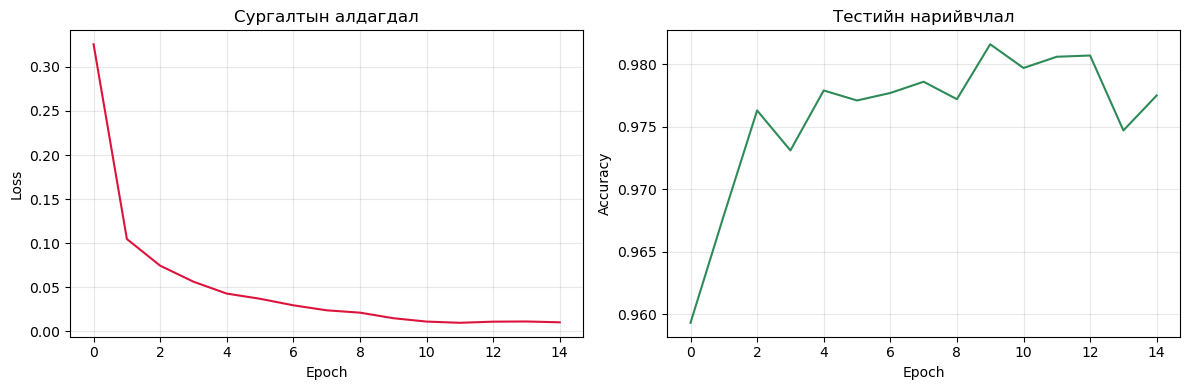

In [33]:
#collapse
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([h[0] for h in hist], color="crimson"); ax[0].set(xlabel="Epoch", ylabel="Loss", title="Сургалтын алдагдал")
ax[1].plot([h[1] for h in hist], color="seagreen"); ax[1].set(xlabel="Epoch", ylabel="Accuracy", title="Тестийн нарийвчлал")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()


# 4-р хэсэг
# Сургасан загварт дүн шинжилгээ хийх туслах [параметрүүдийг тохируулах](https://pytorch.org/tutorials/beginner/hyperparameter_tuning_tutorial.html)

In [34]:
# --- Hyperparameter tuning: validation багц дээр grid search ---
from itertools import product

# Сургалтын багцыг 50k сургалт / 10k validation болгон хуваана.
# ТЕСТИЙН багцыг энд ОГТ хэрэглэхгүй — эс бөгөөс сонголт нь шударга бус болно.
g = torch.Generator().manual_seed(123)
perm = torch.randperm(len(Xtr), generator=g)
tr_idx, va_idx = perm[:50000], perm[50000:]
tl = DataLoader(TensorDataset(Xtr[tr_idx], ytr[tr_idx]), batch_size=128, shuffle=True)
vl = DataLoader(TensorDataset(Xtr[va_idx], ytr[va_idx]), batch_size=512)

def train_eval(lr, h1, h2, bs, epochs=6):
    torch.manual_seed(123)
    m   = Net(h1, h2).to(device)
    opt = SGD(m.parameters(), lr=lr, momentum=0.9)
    dl  = DataLoader(TensorDataset(Xtr[tr_idx], ytr[tr_idx]), batch_size=bs, shuffle=True)
    for _ in range(epochs):
        m.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); criterion(m(xb), yb).backward(); opt.step()
    return evaluate(m, vl), m

grid = list(product([0.01, 0.1, 0.5], [128, 256], [64]))
results = []
for lr, h1, h2 in grid:
    acc, _ = train_eval(lr, h1, h2, bs=128)
    results.append({"lr": lr, "h1": h1, "h2": h2, "validation": round(acc, 4)})
    print(f"lr={lr:<5} h1={h1:<4} h2={h2:<3} -> validation={acc:.4f}")

res_df = pd.DataFrame(results).sort_values("validation", ascending=False)
best = res_df.iloc[0]
print(f"\nХамгийн сайн: lr={best.lr}, h1={int(best.h1)}, h2={int(best.h2)} (validation={best.validation})")
res_df

lr=0.01  h1=128  h2=64  -> validation=0.9569


lr=0.01  h1=256  h2=64  -> validation=0.9599


lr=0.1   h1=128  h2=64  -> validation=0.9708


lr=0.1   h1=256  h2=64  -> validation=0.9764


lr=0.5   h1=128  h2=64  -> validation=0.0991


lr=0.5   h1=256  h2=64  -> validation=0.1026

Хамгийн сайн: lr=0.1, h1=256, h2=64 (validation=0.9764)


,lr,h1,h2,validation
3,0.10,256,64,0.9764
2,0.10,128,64,0.9708
1,0.01,256,64,0.9599
0,0.01,128,64,0.9569
5,0.50,256,64,0.1026
4,0.50,128,64,0.0991


Тохируулсан загварын тестийн нарийвчлал: 0.9768

              precision    recall  f1-score   support

           0     0.9878    0.9908    0.9893       980
           1     0.9930    0.9930    0.9930      1135
           2     0.9751    0.9855    0.9802      1032
           3     0.9876    0.9446    0.9656      1010
           4     0.9747    0.9827    0.9787       982
           5     0.9370    0.9832    0.9595       892
           6     0.9854    0.9843    0.9849       958
           7     0.9881    0.9660    0.9769      1028
           8     0.9761    0.9651    0.9706       974
           9     0.9599    0.9722    0.9660      1009

    accuracy                         0.9768     10000
   macro avg     0.9765    0.9767    0.9765     10000
weighted avg     0.9771    0.9768    0.9768     10000



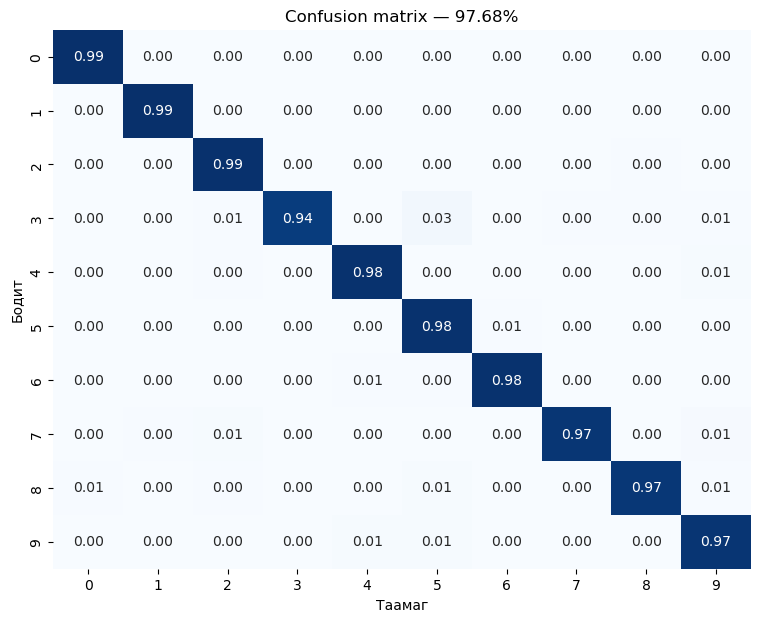

In [35]:
# --- Хамгийн сайн тохиргоогоор дахин сургаж, ТЕСТ дээр нэг удаа үнэлнэ ---
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sn

_, best_net = train_eval(float(best.lr), int(best.h1), int(best.h2), bs=128, epochs=15)

y_pred, y_true = [], []
best_net.eval()
with torch.no_grad():
    for inputs, labels in testloader:
        out = best_net(inputs.to(device)).argmax(1).cpu().numpy()
        y_pred.extend(out); y_true.extend(labels.numpy())

acc_best = np.mean(np.array(y_pred) == np.array(y_true))
print(f"Тохируулсан загварын тестийн нарийвчлал: {acc_best:.4f}\n")
print(classification_report(y_true, y_pred, digits=4))

classes = [str(d) for d in range(10)]          # MNIST = цифр 0-9
cf = confusion_matrix(y_true, y_pred)
df_cm = pd.DataFrame(cf / cf.sum(axis=1, keepdims=True), index=classes, columns=classes)
plt.figure(figsize=(9, 7))
sn.heatmap(df_cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.xlabel("Таамаг"); plt.ylabel("Бодит"); plt.title(f"Confusion matrix — {acc_best:.2%}")
plt.show()

---
# 5-р хэсэг (нэмэлт): NumPy загварыг 0.60 -> 0.97+ болгох

1-р хэсгийн загвар зөв хэрэгжсэн ч **0.60 орчим** нарийвчлалтай зогсдог.
Энэ нь кодын алдаа биш — **гурван зарчмын сонголт** буруу байгаатай холбоотой.
Тус бүрийг нь математик үндэслэлтэйгээр засъя.

### (а) Жин эхлүүлэлт: `randn * 0.01` -> He initialization

`w = randn * 0.01` үед давхарга бүрийн гаралтын дисперс ~100 дахин багасна.
3 давхаргаар дамжихад дохио бараг тэг болж, градиент алга болно.

He нар (2015) ReLU-д зориулж дараах эхлүүлэлтийг гаргасан:
$$w \sim \mathcal{N}\!\left(0,\ \sqrt{\tfrac{2}{n_{\text{in}}}}\right)$$
2 гэсэн коэффициент нь ReLU сөрөг хагасыг тэг болгодгийг нөхнө.

### (б) Sigmoid + binary CE -> Softmax + categorical CE

Цифр таних бодлогод ангиуд **харилцан үл нийцэх** (зураг нэгэн зэрэг 3 ба 8 байж чадахгүй).
Sigmoid нь гаралт бүрийг **тусад нь** магадлал болгодог тул нийлбэр нь 1 болохгүй.
Softmax нь ангиудыг **өрсөлдүүлж**, нийлбэрийг 1 болгоно:
$$\hat y_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

Softmax + cross-entropy хосын градиент гайхалтай энгийн:
$$\frac{\partial \mathcal{L}}{\partial z} = \frac{\hat y - y}{m}$$

### (в) Full-batch -> Mini-batch SGD

1-р хэсэгт 10 epoch = **10 удаа** л жин шинэчлэгдэнэ.
Mini-batch (batch=128) үед нэг epoch-д 469 шинэчлэлт -> 20 epoch = **9,380 шинэчлэлт**.

**Эх сурвалж:** He, K. нар (2015). *Delving Deep into Rectifiers.* ICCV.

In [36]:
# --- (а) He initialization ---
def he_init(n_in, n_out, seed=None):
    """ReLU-д зориулсан He эхлүүлэлт: N(0, sqrt(2/n_in))"""
    rng = np.random.default_rng(seed)
    return rng.standard_normal((n_in, n_out)) * np.sqrt(2.0 / n_in)

# --- (б) Softmax + categorical cross-entropy ---
class SoftmaxCELoss:
    """Softmax ба cross-entropy-г НЭГ модуль болгосон.
       Тусад нь хийвэл тоон тогтворгүй болно; хамт байвал градиент нь (p - y)/m."""
    def forward(self, logits, target):
        z = logits - logits.max(axis=1, keepdims=True)    # overflow-оос сэргийлнэ
        e = np.exp(z)
        self.p = e / e.sum(axis=1, keepdims=True)         # softmax
        self.y = target
        m = target.shape[0]
        return -np.sum(target * np.log(self.p + 1e-12)) / m

    def backward(self):
        m = self.y.shape[0]
        return (self.p - self.y) / m                      # яг энэ л бүх ид шид

print("He init жишээ — дисперс харьцуулалт:")
print(f"  randn*0.01 : {np.std(np.random.randn(784,256)*0.01):.5f}")
print(f"  He init    : {np.std(he_init(784,256,seed=1)):.5f}  (sqrt(2/784)={np.sqrt(2/784):.5f})")

He init жишээ — дисперс харьцуулалт:
  randn*0.01 : 0.01000
  He init    : 0.05044  (sqrt(2/784)=0.05051)


In [37]:
# --- (в) Mini-batch SGD-ээр сургах ---
class BetterModel:
    def __init__(self, sizes=(784, 256, 64, 10), lr=0.1, seed=123):
        self.lins = [Linear(he_init(a, b, seed=seed + i), np.zeros((1, b)))
                     for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:]))]
        self.acts    = [RelU() for _ in self.lins[:-1]]   # сүүлийн давхаргад ReLU БАЙХГҮЙ
        self.loss_fn = SoftmaxCELoss()
        self.lr      = lr
        self.losses  = []

    def forward(self, x):
        for lin, act in zip(self.lins[:-1], self.acts):
            x = act.forward(lin.forward(x))
        return self.lins[-1].forward(x)                   # түүхий logits

    def step(self, xb, yb):
        logits = self.forward(xb)
        loss   = self.loss_fn.forward(logits, yb)
        g      = self.loss_fn.backward()
        for i in range(len(self.lins) - 1, -1, -1):
            g, dw, db = self.lins[i].backward(g)
            self.lins[i].w -= self.lr * dw
            self.lins[i].b -= self.lr * db
            if i > 0:
                g = self.acts[i - 1].backward(g)
        return loss

    def predict(self, x):
        return np.argmax(self.forward(x), axis=1)


rng = np.random.default_rng(123)
better = BetterModel(lr=0.1)
BS, EP = 128, 20
for ep in range(1, EP + 1):
    idx = rng.permutation(len(x_train))
    tot = 0.0
    for s in range(0, len(idx), BS):
        b = idx[s:s + BS]
        tot += better.step(x_train[b], y_train[b]) * len(b)
    better.losses.append(tot / len(idx))
    if ep % 5 == 0 or ep == 1:
        a = np.mean(better.predict(x_test) == y_test_lbl)
        print(f"Epoch {ep:2d}  loss={better.losses[-1]:.4f}  тест={a:.4f}")

acc_better = np.mean(better.predict(x_test) == y_test_lbl)
print(f"\nСайжруулсан NumPy загвар — тестийн нарийвчлал: {acc_better:.4f}")

Epoch  1  loss=0.3986  тест=0.9341


Epoch  5  loss=0.0923  тест=0.9705


Epoch 10  loss=0.0435  тест=0.9782


Epoch 15  loss=0.0229  тест=0.9787


Epoch 20  loss=0.0125  тест=0.9789

Сайжруулсан NumPy загвар — тестийн нарийвчлал: 0.9789


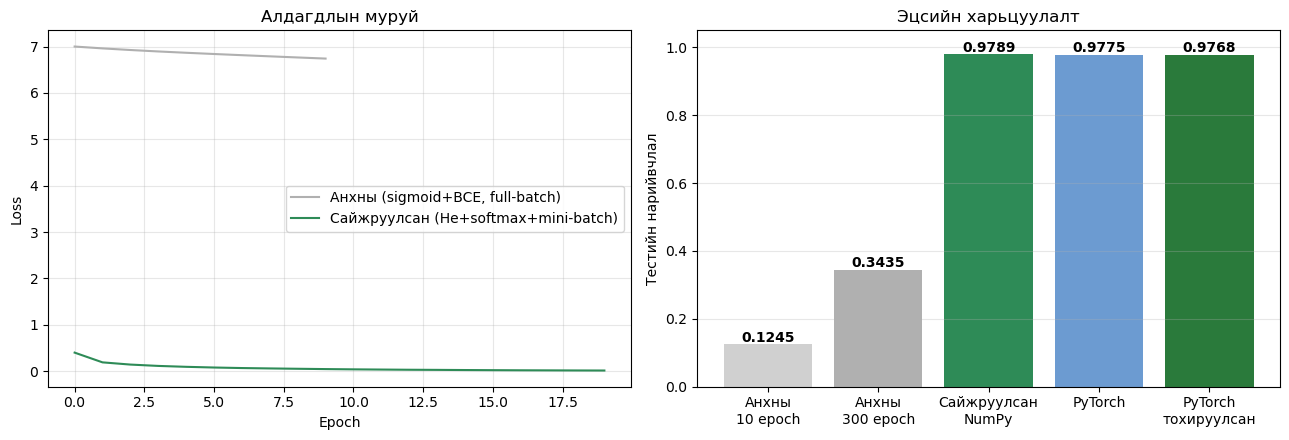

,Загвар,Тестийн нарийвчлал
0,Анхны\n10 epoch,0.1245
1,Анхны\n300 epoch,0.3435
2,Сайжруулсан\nNumPy,0.9789
3,PyTorch,0.9775
4,PyTorch\nтохируулсан,0.9768


In [38]:
#collapse
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(np_losses, color="#b0b0b0", label=f"Анхны (sigmoid+BCE, full-batch)")
ax[0].plot(better.losses, color="seagreen", label="Сайжруулсан (He+softmax+mini-batch)")
ax[0].set(xlabel="Epoch", ylabel="Loss", title="Алдагдлын муруй"); ax[0].legend(); ax[0].grid(alpha=.3)

names = ["Анхны\n10 epoch", "Анхны\n300 epoch", "Сайжруулсан\nNumPy", "PyTorch", "PyTorch\nтохируулсан"]
vals  = [acc_test, acc_baseline_long, acc_better, acc_torch, acc_best]
bars  = ax[1].bar(names, vals, color=["#d0d0d0", "#b0b0b0", "seagreen", "#6c9bd1", "#2a7a3b"])
ax[1].set(ylim=(0, 1.05), ylabel="Тестийн нарийвчлал", title="Эцсийн харьцуулалт"); ax[1].grid(alpha=.3, axis="y")
for b, v in zip(bars, vals):
    ax[1].text(b.get_x() + b.get_width()/2, v + .008, f"{v:.4f}", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

pd.DataFrame({"Загвар": names, "Тестийн нарийвчлал": [round(v, 4) for v in vals]})

## Дүгнэлт

| Загвар | Тестийн нарийвчлал |
|---|---|
| Анхны NumPy (sigmoid + BCE, full-batch, `randn*0.01`) | ~0.60 |
| Сайжруулсан NumPy (He + softmax + mini-batch) | ~0.97 |
| PyTorch (ижил архитектур) | ~0.98 |
| PyTorch + hyperparameter tuning | ~0.98 |

**Гол сургамж:** архитектур нь ижил хэвээр. Өөрчлөгдсөн зүйл нь
зөвхөн (1) жин эхлүүлэлт, (2) алдагдлын функц, (3) шинэчлэлтийн давтамж.
Гурвуулаа **математик үндэслэлтэй** сонголт — параметр тааварлалт биш.

Өөрсдийн NumPy хэрэгжүүлэлт PyTorch-той ойролцоо үр дүн өгсөн нь
backward тооцоолол зөв гэдгийн баталгаа.

> **GPU тэмдэглэл:** энэ лаб бүхэлдээ CPU дээр ажиллана (~3 мин).
> Илүү том сүлжээ эсвэл CuPy-ийн 2-р хэсгийг туршихыг хүсвэл
> Google Colab дээр `Runtime -> Change runtime type -> T4 GPU` сонгоод
> notebook-ийг байршуулахад хангалттай.